# M6 Assignment Solution

**Kapil Kumar Sharma**

**NET ID: apl25002**

**Date: 14-10-2026**

# Logistic Regression
**Jennifer Eigo - University of Connecticut - Dept. of Operations and Information Management**

-------------------------------------
Regression models are commonly used models in data science. They are very explainable so you not only build a model, but you also learn more about relationships in the data. Logistic regressions predict a categorical target variable.


# Environment Setup

In [ ]:
# import modules

import pandas as pd # for data viz and wrangling
import numpy as np # for 'numeric python'
import matplotlib.pyplot as plt # for data viz (more complex than pylab)
import seaborn as sns
from pylab import * # for data viz (import * means 'import all of the functions')
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import f_regression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn import metrics
from scipy import stats
import statsmodels.api as sm


# (1) Read in the dataset and determine how many rows and columns it has.

To practice logistic regression, we need a dataset that has a categorical target.  The Telco_customer_churn dataset can be used to predict if a customer will leave/churn or Not.  Each row represents a Telco customer and the target variable is called 'Churn Label'.

In [ ]:
# read data
# on the lefthand side, navigate to your data and copy the path
df = pd.read_csv('Telco_customer_churn.csv')

In [ ]:
# shape
# shows how many rows and columns
df.shape
rows, columns = df.shape
print("Rows:", rows)
print("Columns:", columns)

Rows: 7043
Columns: 18


In [ ]:
# Preview
print(df.head())

   CustomerID  Gender Senior Citizen Partner Dependents  Tenure Months  \
0  3668-QPYBK    Male             No      No         No              2   
1  9237-HQITU  Female             No      No        Yes              2   
2  9305-CDSKC  Female             No      No        Yes              8   
3  7892-POOKP  Female             No     Yes        Yes             28   
4  0280-XJGEX    Male             No      No        Yes             49   

  Multiple Lines Internet Service Online Security Online Backup  \
0             No              DSL             Yes           Yes   
1             No      Fiber optic              No            No   
2            Yes      Fiber optic              No            No   
3            Yes      Fiber optic              No            No   
4            Yes      Fiber optic              No           Yes   

  Device Protection Tech Support        Contract Paperless Billing  \
0                No           No  Month-to-month               Yes   
1           

# (2) The target variable for this dataset is the churn column.  Check the datatypes of the predictor variables.  Make dummy variables if needed.

In [ ]:
# list the columns with the data types
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Gender             7043 non-null   object 
 2   Senior Citizen     7043 non-null   object 
 3   Partner            7043 non-null   object 
 4   Dependents         7043 non-null   object 
 5   Tenure Months      7043 non-null   int64  
 6   Multiple Lines     7043 non-null   object 
 7   Internet Service   7043 non-null   object 
 8   Online Security    7043 non-null   object 
 9   Online Backup      7043 non-null   object 
 10  Device Protection  7043 non-null   object 
 11  Tech Support       7043 non-null   object 
 12  Contract           7043 non-null   object 
 13  Paperless Billing  7043 non-null   object 
 14  Electronic Check   7043 non-null   object 
 15  Monthly Charges    7043 non-null   float64
 16  Churn Label        7043 

In [ ]:
target = df['Churn Label']

exclude_columns = [
    'CustomerID',
    'Churn Label',
    'Churn Value'
]

features = df.drop(columns=exclude_columns)

We have mix of categorical and continuous predictors.  We should  change our target variable to 1s and 0s.  And let's make dummy variables for Education.  We should drop Zip Code because it has too many categories.  

In [ ]:
features = pd.get_dummies(
    features,
    drop_first=True
)

In [ ]:
features.dtypes

,0
Tenure Months,int64
Monthly Charges,float64
Gender_Male,bool
Senior Citizen_Yes,bool
Partner_Yes,bool
Dependents_Yes,bool
Multiple Lines_No phone service,bool
Multiple Lines_Yes,bool
Internet Service_Fiber optic,bool
Internet Service_No,bool


In [ ]:
# We gave now have numeric predictors only.
features.shape

(7043, 18)

In [ ]:
target = df['Churn Label'].map({'Yes': 1, 'No': 0})
print(target)

0       1
1       1
2       1
3       1
4       1
       ..
7038    0
7039    0
7040    0
7041    0
7042    0
Name: Churn Label, Length: 7043, dtype: int64


In [ ]:
features.head()

,Tenure Months,Monthly Charges,Gender_Male,Senior Citizen_Yes,Partner_Yes,Dependents_Yes,Multiple Lines_No phone service,Multiple Lines_Yes,Internet Service_Fiber optic,Internet Service_No,Online Security_Yes,Online Backup_Yes,Device Protection_Yes,Tech Support_Yes,Contract_One year,Contract_Two year,Paperless Billing_Yes,Electronic Check_Yes
0,2,53.85,True,False,False,False,False,False,False,False,True,True,False,False,False,False,True,False
1,2,70.70,False,False,False,True,False,False,True,False,False,False,False,False,False,False,True,True
2,8,99.65,False,False,False,True,False,True,True,False,False,False,True,False,False,False,True,True
3,28,104.80,False,False,True,True,False,True,True,False,False,False,True,True,False,False,True,True
4,49,103.70,True,False,False,True,False,True,True,False,False,True,True,False,False,False,True,False


# (3) Partition the data into a 60/20/20 split.

Now let's partition the data to get it ready for modeling. We define Churn Label as the target variable and the rest of the columns as our predictor variables.  We will do a 60/20/20 split.  

In the code we first separate out the 20% for test, then we split the remaining portion into training and validation.

In [ ]:
from sklearn.model_selection import train_test_split

# Split the data into 80% training and 20% test
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

# Split the 80% training data into 60% training and 20% validation
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42) # 0.25 * 0.8 = 0.6

# Print the shapes of the resulting datasets
print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (4225, 18) (4225,)
Validation set shape: (1409, 18) (1409,)
Test set shape: (1409, 18) (1409,)


# (4) Build a logistic regression model to predict churn using all predictors.

First we fit the model.

In [ ]:
# Initialize and train the Logistic Regression model
logistic_model = LogisticRegression(random_state=42, max_iter=5000)
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


Then we make predictions using the formula that was fitted on the training data.

In [ ]:
# Make predictions (classes) on the training, validation, and test sets
y_train_pred = logistic_model.predict(X_train)
y_val_pred = logistic_model.predict(X_val)
y_test_pred = logistic_model.predict(X_test)

# Get predicted probabilities for the training, validation, and test sets
y_train_proba = logistic_model.predict_proba(X_train)[:, 1] # Probability of the positive class (1)
y_val_proba = logistic_model.predict_proba(X_val)[:, 1]
y_test_proba = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions (classes and probabilities) made successfully on training, validation, and test sets.")

Predictions (classes and probabilities) made successfully on training, validation, and test sets.


Let's take a look at the predictions.  Notice how the model predicts probabilities which are then converted to classes based off a default cutoff of 0.5.

In [ ]:
# Show actuals, probabilities, and predictions for the first 10 rows of the test set in a DataFrame
import pandas as pd

results_df = pd.DataFrame({
    'Actual': y_test.head(10).tolist(),
    'Churn Probability ( 1 = Yes)': y_test_proba[:10].tolist(),
    'Churn Class': y_test_pred[:10].tolist()
})

print("Actuals, Probabilities, and Predicted Personal Loan (First 10 rows of Test Set):")
display(results_df)

Actuals, Probabilities, and Predicted Personal Loan (First 10 rows of Test Set):


,Actual,Churn Probability ( 1 = Yes),Churn Class
0,1,0.576398,1
1,0,0.338861,0
2,0,0.238268,0
3,1,0.782586,1
4,1,0.299774,0
5,1,0.846037,1
6,0,0.861742,1
7,1,0.412216,0
8,1,0.563032,1
9,0,0.043797,0


Since only two of the rows above have a probability near 0.5, let's check again and be more specific.

In [ ]:
# Filter the test set to show rows where predicted probability is between 0.45 and 0.55
uncertain_predictions_indices = (y_test_proba >= 0.45) & (y_test_proba <= 0.55)

# Get the corresponding actual values, predicted probabilities, and predicted classes
uncertain_actual = y_test[uncertain_predictions_indices]
uncertain_proba = y_test_proba[uncertain_predictions_indices]
uncertain_pred = y_test_pred[uncertain_predictions_indices]

# Create a DataFrame to display these results
uncertain_results_df = pd.DataFrame({
    'Actual': uncertain_actual,
    'Churn Probability ( 1 = Yes)': uncertain_proba,
    'Churn Class': uncertain_pred
})

# Display the first 10 rows from this filtered DataFrame
print("Test Set Rows with Predicted Probability between 0.45 and 0.55 (First 10):")
display(uncertain_results_df.head(10))

# Also show the number of such cases
print(f"\nNumber of cases with predicted probability between 0.45 and 0.55 in the test set: {len(uncertain_results_df)}")

Test Set Rows with Predicted Probability between 0.45 and 0.55 (First 10):


,Actual,Churn Probability ( 1 = Yes),Churn Class
1345,1,0.537630,1
1817,1,0.549675,1
2164,0,0.455721,0
3658,0,0.538834,1
3172,0,0.531159,1
535,1,0.452698,0
1042,1,0.518660,1
319,1,0.509871,1
5955,0,0.513817,1
764,1,0.461607,0



Number of cases with predicted probability between 0.45 and 0.55 in the test set: 97


Now we can see the 0.5 cutoff in action.  

Let's also take a look at the coefficients.  Just like before we can learn about our predictors by assessing the sign of the coefficients.  

Positive coefficients make people more likely to Churn.  Negative coefficients make people less likely to Churn/leave.  

In [ ]:
# Show the coefficients of the logistic regression model, including the intercept
feature_names = X_train.columns
coefficients = logistic_model.coef_[0]
intercept = logistic_model.intercept_[0]

# Create a DataFrame for coefficients and feature names
coef_df = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefficients})

# Add the intercept to the DataFrame
intercept_df = pd.DataFrame({'Feature': ['Intercept'], 'Coefficient': [intercept]})
coef_df = pd.concat([intercept_df, coef_df], ignore_index=True)

print("\nCoefficients (including Intercept) with Feature Names:")
print(coef_df)


Coefficients (including Intercept) with Feature Names:
                            Feature  Coefficient
0                         Intercept    -1.726693
1                     Tenure Months    -0.037971
2                   Monthly Charges     0.025024
3                       Gender_Male    -0.047703
4                Senior Citizen_Yes     0.108061
5                       Partner_Yes     0.263202
6                    Dependents_Yes    -1.423043
7   Multiple Lines_No phone service     0.948745
8                Multiple Lines_Yes     0.247225
9      Internet Service_Fiber optic     0.155696
10              Internet Service_No    -0.301334
11              Online Security_Yes    -0.535179
12                Online Backup_Yes    -0.142314
13            Device Protection_Yes    -0.065753
14                 Tech Support_Yes    -0.514860
15                Contract_One year    -0.611460
16                Contract_Two year    -1.152517
17            Paperless Billing_Yes     0.441285
18           

In [ ]:
# Show the regression formula
# The formula for logistic regression is: log(p / (1 - p)) = b0 + b1*x1 + b2*x2 + ... + bn*xn
# Rearranging for p: p = 1 / (1 + exp(-(b0 + b1*x1 + b2*x2 + ... + bn*xn)))

intercept = logistic_model.intercept_[0]

linear_combination = f"{intercept:.4f}"
for i, feature in enumerate(feature_names):
    linear_combination += f" + {coefficients[i]:.4f}*{feature}"

formula = f"p = 1 / (1 + exp(-({linear_combination})))"

print("Logistic Regression Formula (with probability on the left):")
print(formula)

Logistic Regression Formula (with probability on the left):
p = 1 / (1 + exp(-(-1.7267 + -0.0380*Tenure Months + 0.0250*Monthly Charges + -0.0477*Gender_Male + 0.1081*Senior Citizen_Yes + 0.2632*Partner_Yes + -1.4230*Dependents_Yes + 0.9487*Multiple Lines_No phone service + 0.2472*Multiple Lines_Yes + 0.1557*Internet Service_Fiber optic + -0.3013*Internet Service_No + -0.5352*Online Security_Yes + -0.1423*Online Backup_Yes + -0.0658*Device Protection_Yes + -0.5149*Tech Support_Yes + -0.6115*Contract_One year + -1.1525*Contract_Two year + 0.4413*Paperless Billing_Yes + 0.3500*Electronic Check_Yes)))


It's always important to look at the confusion matrixes so let's start there.

Confusion Matrix - Training Set:
[[2777  327]
 [ 458  663]]

Confusion Matrix - Validation Set:
[[962  99]
 [162 186]]

Confusion Matrix - Test Set:
[[897 112]
 [167 233]]


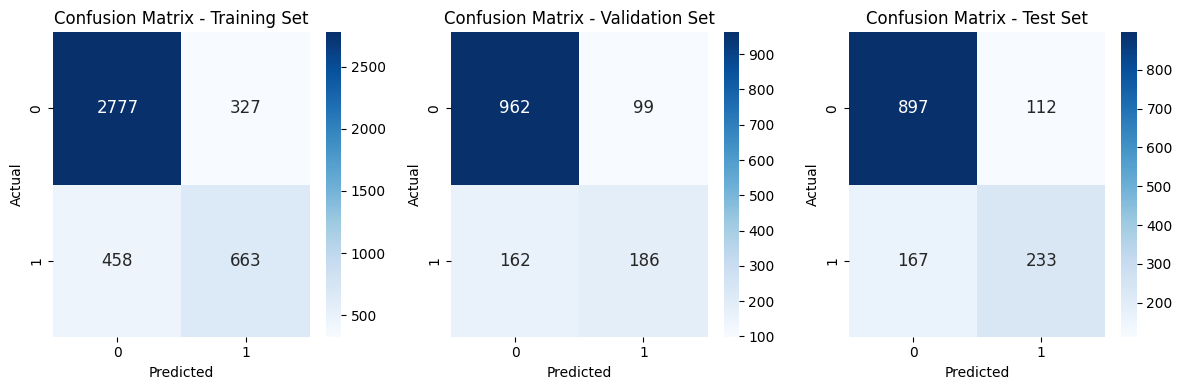

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate confusion matrix for the training set
cm_train = confusion_matrix(y_train, y_train_pred)
print("Confusion Matrix - Training Set:")
print(cm_train)

# Calculate confusion matrix for the validation set
cm_val = confusion_matrix(y_val, y_val_pred)
print("\nConfusion Matrix - Validation Set:")
print(cm_val)

# Calculate confusion matrix for the test set
cm_test = confusion_matrix(y_test, y_test_pred)
print("\nConfusion Matrix - Test Set:")
print(cm_test)

# Optional: Visualize Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', ax=axes[0], annot_kws={"size": 12})
axes[0].set_title('Confusion Matrix - Training Set')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(cm_val, annot=True, fmt='d', cmap='Blues', ax=axes[1], annot_kws={"size": 12})
axes[1].set_title('Confusion Matrix - Validation Set')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', ax=axes[2], annot_kws={"size": 12})
axes[2].set_title('Confusion Matrix - Test Set')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')

plt.tight_layout()
plt.show()

# (5) Check model performance by partition with total accuracy, precision, recall, F1 score, and AUC.

Now let's look at the classification report which shows the important model performance metrics.

In [ ]:
from sklearn.metrics import classification_report

# Show classification report for the training set
print("Classification Report - Training Set:")
print(classification_report(y_train, y_train_pred))

# Show classification report for the validation set
print("\nClassification Report - Validation Set:")
print(classification_report(y_val, y_val_pred))

# Show classification report for the test set
print("\nClassification Report - Test Set:")
print(classification_report(y_test, y_test_pred))

Classification Report - Training Set:
              precision    recall  f1-score   support

           0       0.86      0.89      0.88      3104
           1       0.67      0.59      0.63      1121

    accuracy                           0.81      4225
   macro avg       0.76      0.74      0.75      4225
weighted avg       0.81      0.81      0.81      4225


Classification Report - Validation Set:
              precision    recall  f1-score   support

           0       0.86      0.91      0.88      1061
           1       0.65      0.53      0.59       348

    accuracy                           0.81      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.81      0.81      0.81      1409


Classification Report - Test Set:
              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1009
           1       0.68      0.58      0.63       400

    accuracy                           0.80      1409
   macro avg  

Interpretation
- Accuracy: The model correctly classifies about 80–81% of customers across all three partitions.
- Precision: For the test set, precision of 0.68 means that among customers predicted to churn, about 68% actually churned.
- Recall: Test recall of 0.59 means the model identifies about 59% of the actual churners. This is important because the model is missing about 41% of customers who actually churn.
- F1 score: The test F1 score of 0.63 shows a moderate balance between precision and recall for identifying churners.
- Class 0 performs better than Class 1. For example, test recall is 0.89 for non-churners but only 0.59 for churners. This is partly because there are more non-churners than churners in the dataset.

The lift cureve can be helpful if we are looking for a specific improvement over our current response rate.

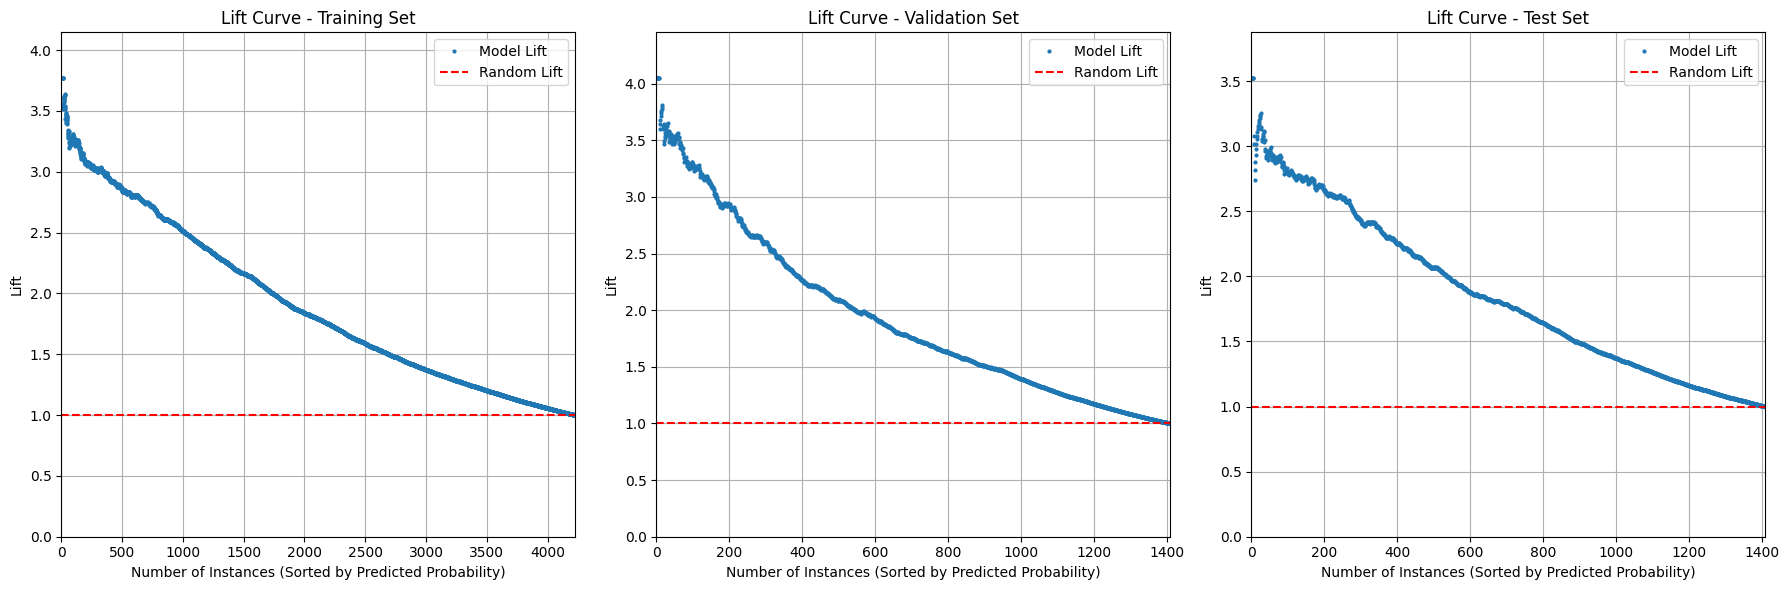

In [ ]:
def plot_lift_curve(y_true, y_proba, title):
    """Plots the lift curve for a binary classification model."""
    # Ensure y_true and y_proba are numpy arrays
    y_true = np.asarray(y_true)
    y_proba = np.asarray(y_proba)

    # Sort the data by predicted probability in descending order
    sorted_indices = np.argsort(y_proba)[::-1]
    y_true_sorted = y_true[sorted_indices]

    # Calculate the cumulative number of positive instances
    cumulative_positives = np.cumsum(y_true_sorted)

    # Calculate the cumulative number of instances
    cumulative_instances = np.arange(1, len(y_true) + 1)

    # Calculate the lift
    # Avoid division by zero by checking if cumulative_instances is 0
    lift = np.where(cumulative_instances > 0, cumulative_positives / cumulative_instances / (np.sum(y_true) / len(y_true)), 0)


    plt.plot(cumulative_instances, lift, marker='.', linestyle='none', markersize=4, label='Model Lift')
    plt.plot([0, len(y_true)], [1, 1], linestyle='--', color='red', label='Random Lift') # Random lift is always 1

    plt.xlabel("Number of Instances (Sorted by Predicted Probability)")
    plt.ylabel("Lift")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.ylim([0, max(lift) * 1.1 if len(lift) > 0 else 2]) # Adjust y-axis limit
    plt.xlim([0, len(y_true)]) # Adjust x-axis limit


# Plot lift curve for each partition
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_lift_curve(y_train, y_train_proba, 'Lift Curve - Training Set')

plt.subplot(1, 3, 2)
plot_lift_curve(y_val, y_val_proba, 'Lift Curve - Validation Set')

plt.subplot(1, 3, 3)
plot_lift_curve(y_test, y_test_proba, 'Lift Curve - Test Set')

plt.tight_layout()
plt.show()

Lastly, let's look at the AUC for each partition.

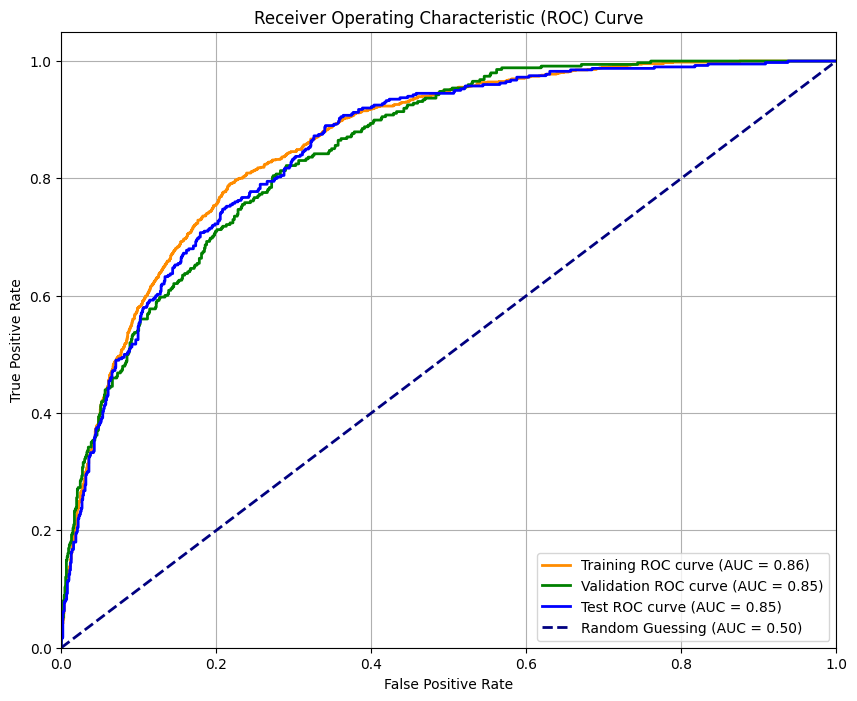

Training AUC: 0.8613
Validation AUC: 0.8499
Test AUC: 0.8528


In [ ]:
# Calculate ROC curve and AUC for the training set
fpr_train, tpr_train, thresholds_train = roc_curve(y_train, y_train_proba)
roc_auc_train = auc(fpr_train, tpr_train)

# Calculate ROC curve and AUC for the validation set
fpr_val, tpr_val, thresholds_val = roc_curve(y_val, y_val_proba)
roc_auc_val = auc(fpr_val, tpr_val)

# Calculate ROC curve and AUC for the test set
fpr_test, tpr_test, thresholds_test = roc_curve(y_test, y_test_proba)
roc_auc_test = auc(fpr_test, tpr_test)

# Plot ROC curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_train, tpr_train, color='darkorange', lw=2, label='Training ROC curve (AUC = %0.2f)' % roc_auc_train)
plt.plot(fpr_val, tpr_val, color='green', lw=2, label='Validation ROC curve (AUC = %0.2f)' % roc_auc_val)
plt.plot(fpr_test, tpr_test, color='blue', lw=2, label='Test ROC curve (AUC = %0.2f)' % roc_auc_test)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guessing (AUC = 0.50)') # Diagonal line for random guessing
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print(f"Training AUC: {roc_auc_train:.4f}")
print(f"Validation AUC: {roc_auc_val:.4f}")
print(f"Test AUC: {roc_auc_test:.4f}")

The logistic regression model achieved AUC values of 0.8611, 0.8501, and 0.8518 for the training, validation, and test sets, respectively.

The test AUC of 0.8518 indicates good ability to distinguish between customers who churn and those who do not. The similar AUC values across the three partitions suggest that the model generalizes well and shows little evidence of overfitting.

# (6) Comment on the model performance.  What did you observe in the results?

The logistic regression model performed consistently across all three partitions, with accuracy of 81% on the training set, 81% on the validation set, and 80% on the test set. This small difference suggests that there is little evidence of overfitting and the model generalizes reasonably well to unseen customers.


For the churn class (1), the test set had 68% precision, 59% recall, and 63% F1 score. This means the model correctly identifies a little more than half of the customers who actually churn, but it still misses about 41% of actual churners.


The model performs better for non-churners (class 0), with 89% recall on the test set, compared with 59% recall for churners. This indicates that the model has more difficulty identifying churners than non-churners, which is an important observation for a business where identifying customers at risk of leaving is the primary objective.


Overall, the model has good and stable accuracy, but there is room for improvement in identifying actual churners, particularly recall for class 1.

# (7) Check for predictor significance.  Are any predictors insignificant?  Which ones?

Variable Selection

We should always check the statistical significance of our predictors with our P values.

In [ ]:
# Convert boolean columns to integers (0s and 1s) for statsmodels
X_train_sm = X_train.astype(int)

# Add a constant (intercept) to the features for statsmodels
X_train_sm = sm.add_constant(X_train_sm)

# Fit the logistic regression model using statsmodels
logit_model = sm.Logit(y_train, X_train_sm)
result = logit_model.fit()

# Show the model summary, which includes p-values
print(result.summary())

Optimization terminated successfully.
         Current function value: 0.397777
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:            Churn Label   No. Observations:                 4225
Model:                          Logit   Df Residuals:                     4206
Method:                           MLE   Df Model:                           18
Date:                Wed, 14 Oct 2026   Pseudo R-squ.:                  0.3125
Time:                        19:26:12   Log-Likelihood:                -1680.6
converged:                       True   LL-Null:                       -2444.4
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const                              -1.7497      0.314     -5.571  

Looks like we could improve the model by removing Age, Income, and Securities Account to start.  Even though Education_Professional has a high P value, Education_Undergrad does not so we will keep that in.  Those numbers are telling us that Professional is not that different from Graduate (the refernce category that was dropped when the dummy variables were formed), while Undergrad is very different.  To address this we could do some additoinal feature engineering and change the education column into two categories - one for Undergrad and one for Graduate/Profesional combined.  Give it a try on your own!

In [ ]:
p_values = result.pvalues

insignificant = p_values[p_values >= 0.05]

print("Insignificant predictors:")
print(insignificant)

Insignificant predictors:
Gender_Male                     0.572676
Senior Citizen_Yes              0.349629
Internet Service_Fiber optic    0.492035
Internet Service_No             0.287196
Online Backup_Yes               0.165903
Device Protection_Yes           0.541930
dtype: float64


At the 5% significance level, six predictors were found to be statistically insignificant: Gender_Male, Senior Citizen_Yes, Internet Service_Fiber optic, Internet Service_No, Online Backup_Yes, and Device Protection_Yes.

Since their p-values are greater than 0.05, there is insufficient statistical evidence that these predictors are associated with customer churn after controlling for the other predictors in the model.


The remaining predictors are statistically significant.

# (8) Re-train the model using just the statistically significant predictors.

In [ ]:
insignificant_predictors = [
    'Gender_Male',
    'Senior Citizen_Yes',
    'Internet Service_Fiber optic',
    'Internet Service_No',
    'Online Backup_Yes',
    'Device Protection_Yes'
]

significant_predictors = [
    col for col in X_train.columns
    if col not in insignificant_predictors
]

print("Number of significant predictors:", len(significant_predictors))
print(significant_predictors)

Number of significant predictors: 12
['Tenure Months', 'Monthly Charges', 'Partner_Yes', 'Dependents_Yes', 'Multiple Lines_No phone service', 'Multiple Lines_Yes', 'Online Security_Yes', 'Tech Support_Yes', 'Contract_One year', 'Contract_Two year', 'Paperless Billing_Yes', 'Electronic Check_Yes']


In [ ]:
X_train_sig = X_train[significant_predictors]
X_val_sig = X_val[significant_predictors]
X_test_sig = X_test[significant_predictors]

logit_model_sig = LogisticRegression(max_iter=1000)

logit_model_sig.fit(X_train_sig, y_train)

y_train_pred_sig = logit_model_sig.predict(X_train_sig)
y_val_pred_sig = logit_model_sig.predict(X_val_sig)
y_test_pred_sig = logit_model_sig.predict(X_test_sig)

y_train_prob_sig = logit_model_sig.predict_proba(X_train_sig)[:, 1]
y_val_prob_sig = logit_model_sig.predict_proba(X_val_sig)[:, 1]
y_test_prob_sig = logit_model_sig.predict_proba(X_test_sig)[:, 1]

# (9) Check model performance again by partition with total accuracy, precision, recall, F1 score, and AUC.

Confusion Matrix - Training Set:
[[2784  320]
 [ 463  658]]

Confusion Matrix - Validation Set:
[[961 100]
 [168 180]]

Confusion Matrix - Test Set:
[[899 110]
 [175 225]]


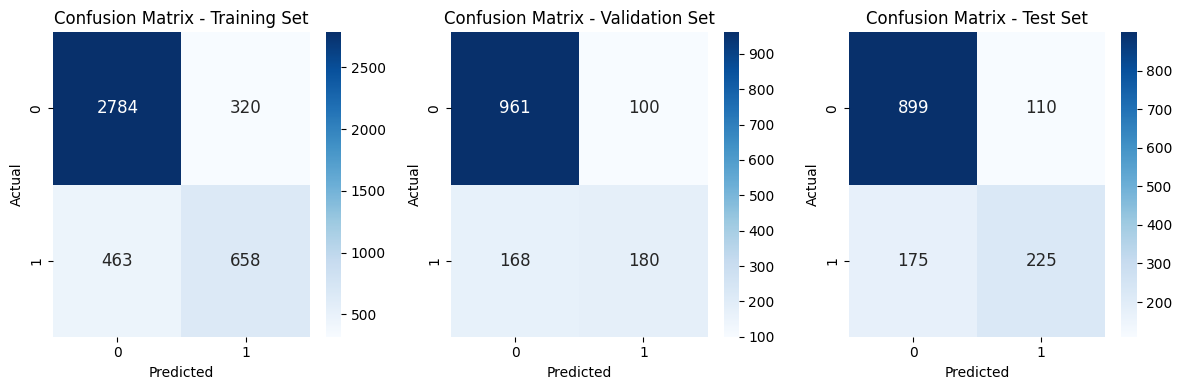

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate confusion matrix for the training set
cm_train = confusion_matrix(y_train, y_train_pred_sig)
print("Confusion Matrix - Training Set:")
print(cm_train)

# Calculate confusion matrix for the validation set
cm_val = confusion_matrix(y_val, y_val_pred_sig)
print("\nConfusion Matrix - Validation Set:")
print(cm_val)

# Calculate confusion matrix for the test set
cm_test = confusion_matrix(y_test, y_test_pred_sig)
print("\nConfusion Matrix - Test Set:")
print(cm_test)

# Optional: Visualize Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', ax=axes[0], annot_kws={"size": 12})
axes[0].set_title('Confusion Matrix - Training Set')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(cm_val, annot=True, fmt='d', cmap='Blues', ax=axes[1], annot_kws={"size": 12})
axes[1].set_title('Confusion Matrix - Validation Set')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', ax=axes[2], annot_kws={"size": 12})
axes[2].set_title('Confusion Matrix - Test Set')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

# Show classification report for the training set
print("Classification Report - Training Set:")
print(classification_report(y_train, y_train_pred_sig))

# Show classification report for the validation set
print("\nClassification Report - Validation Set:")
print(classification_report(y_val, y_val_pred_sig))

# Show classification report for the test set
print("\nClassification Report - Test Set:")
print(classification_report(y_test, y_test_pred_sig))

Classification Report - Training Set:
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      3104
           1       0.67      0.59      0.63      1121

    accuracy                           0.81      4225
   macro avg       0.77      0.74      0.75      4225
weighted avg       0.81      0.81      0.81      4225


Classification Report - Validation Set:
              precision    recall  f1-score   support

           0       0.85      0.91      0.88      1061
           1       0.64      0.52      0.57       348

    accuracy                           0.81      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.80      0.81      0.80      1409


Classification Report - Test Set:
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1009
           1       0.67      0.56      0.61       400

    accuracy                           0.80      1409
   macro avg  

After removing the six statistically insignificant predictors, the model's overall performance remained relatively stable.

Test accuracy remained at 80%, while precision for churners decreased slightly from 68% to 67%, recall decreased from 59% to 56%, and F1 score decreased from 63% to 61%.

Therefore, removing the insignificant predictors resulted in a small decrease in predictive performance, particularly in identifying actual churners.

However, the reduced model is more parsimonious while maintaining similar overall accuracy.

The lift cureve can be helpful if we are looking for a specific improvement over our current response rate.

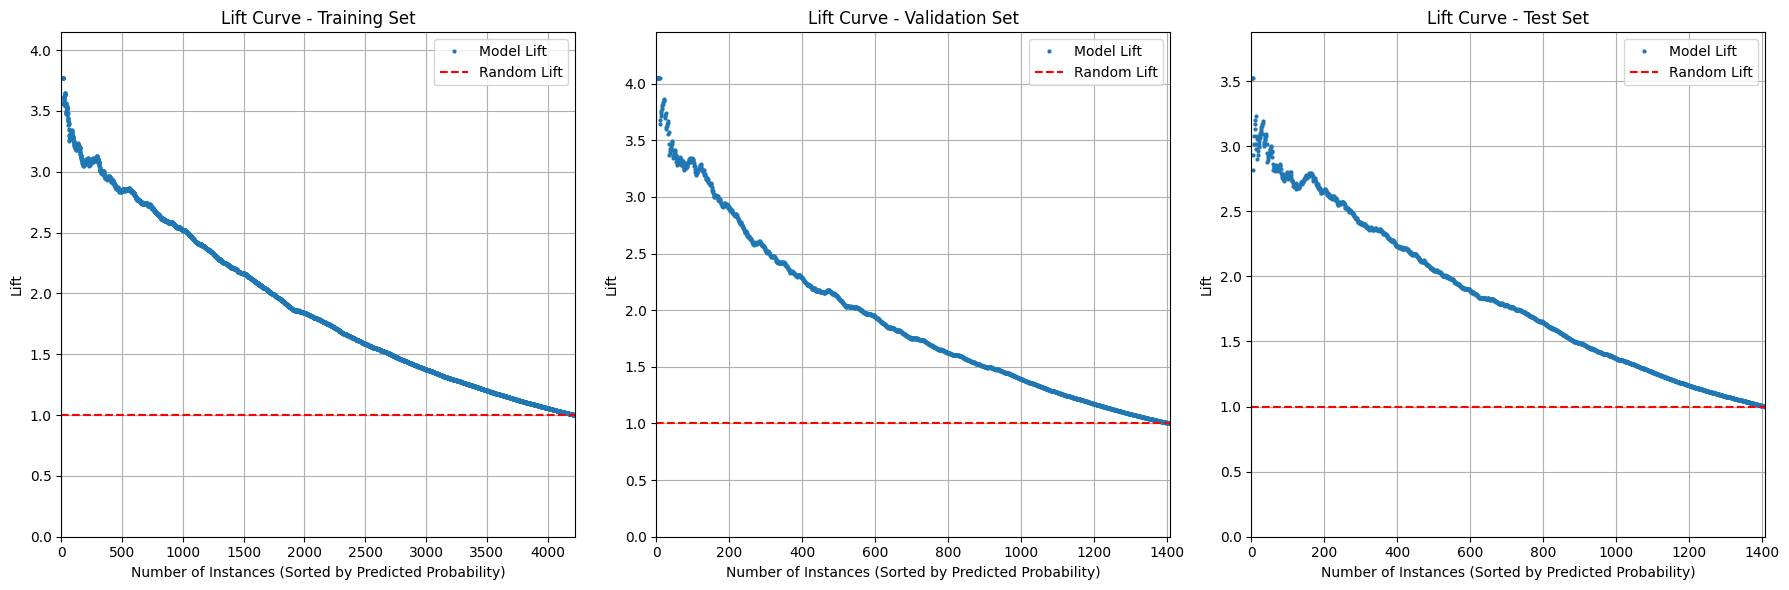

In [ ]:
def plot_lift_curve(y_true, y_proba, title):
    """Plots the lift curve for a binary classification model."""
    # Ensure y_true and y_proba are numpy arrays
    y_true = np.asarray(y_true)
    y_proba = np.asarray(y_proba)

    # Sort the data by predicted probability in descending order
    sorted_indices = np.argsort(y_proba)[::-1]
    y_true_sorted = y_true[sorted_indices]

    # Calculate the cumulative number of positive instances
    cumulative_positives = np.cumsum(y_true_sorted)

    # Calculate the cumulative number of instances
    cumulative_instances = np.arange(1, len(y_true) + 1)

    # Calculate the lift
    # Avoid division by zero by checking if cumulative_instances is 0
    lift = np.where(cumulative_instances > 0, cumulative_positives / cumulative_instances / (np.sum(y_true) / len(y_true)), 0)


    plt.plot(cumulative_instances, lift, marker='.', linestyle='none', markersize=4, label='Model Lift')
    plt.plot([0, len(y_true)], [1, 1], linestyle='--', color='red', label='Random Lift') # Random lift is always 1

    plt.xlabel("Number of Instances (Sorted by Predicted Probability)")
    plt.ylabel("Lift")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.ylim([0, max(lift) * 1.1 if len(lift) > 0 else 2]) # Adjust y-axis limit
    plt.xlim([0, len(y_true)]) # Adjust x-axis limit


# Plot lift curve for each partition
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plot_lift_curve(y_train, y_train_prob_sig, 'Lift Curve - Training Set')

plt.subplot(1, 3, 2)
plot_lift_curve(y_val, y_val_prob_sig, 'Lift Curve - Validation Set')

plt.subplot(1, 3, 3)
plot_lift_curve(y_test, y_test_prob_sig, 'Lift Curve - Test Set')

plt.tight_layout()
plt.show()

Lastly, let's look at the AUC for each partition.

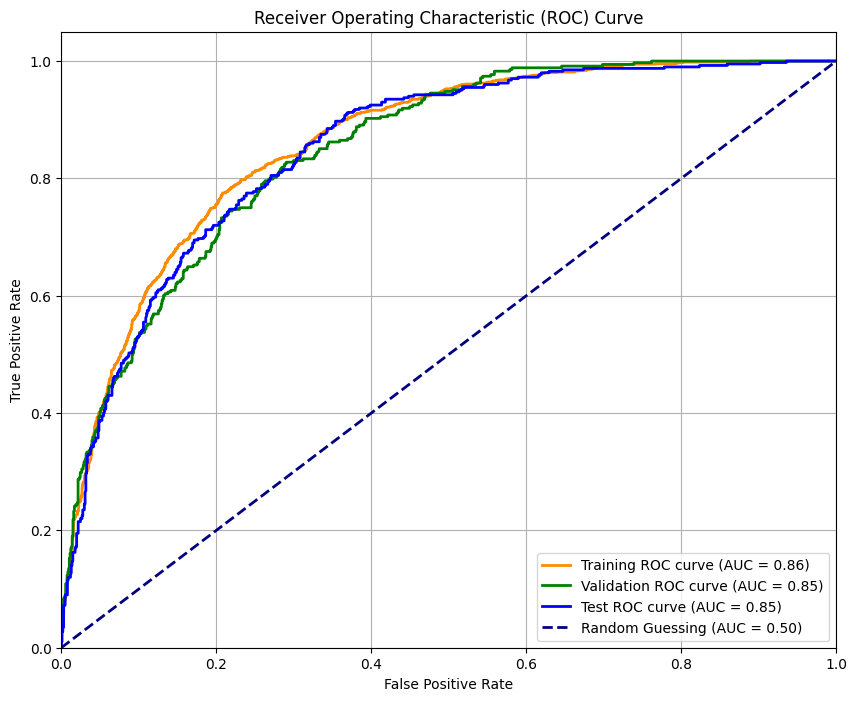

Training AUC: 0.8606
Validation AUC: 0.8493
Test AUC: 0.8510


In [ ]:
# Calculate ROC curve and AUC for the training set
fpr_train, tpr_train, thresholds_train = roc_curve(y_train, y_train_prob_sig)
roc_auc_train = auc(fpr_train, tpr_train)

# Calculate ROC curve and AUC for the validation set
fpr_val, tpr_val, thresholds_val = roc_curve(y_val, y_val_prob_sig)
roc_auc_val = auc(fpr_val, tpr_val)

# Calculate ROC curve and AUC for the test set
fpr_test, tpr_test, thresholds_test = roc_curve(y_test, y_test_prob_sig)
roc_auc_test = auc(fpr_test, tpr_test)

# Plot ROC curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_train, tpr_train, color='darkorange', lw=2, label='Training ROC curve (AUC = %0.2f)' % roc_auc_train)
plt.plot(fpr_val, tpr_val, color='green', lw=2, label='Validation ROC curve (AUC = %0.2f)' % roc_auc_val)
plt.plot(fpr_test, tpr_test, color='blue', lw=2, label='Test ROC curve (AUC = %0.2f)' % roc_auc_test)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guessing (AUC = 0.50)') # Diagonal line for random guessing
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print(f"Training AUC: {roc_auc_train:.4f}")
print(f"Validation AUC: {roc_auc_val:.4f}")
print(f"Test AUC: {roc_auc_test:.4f}")

* The AUC decreased very slightly after removing the statistically insignificant predictors.

After removing the statistically insignificant predictors, AUC decreased slightly from 0.8611 to 0.8606 for training, from 0.8501 to 0.8493 for validation, and from 0.8518 to 0.8510 for the test set.

The decrease in test AUC was only 0.0008, indicating that removing the insignificant predictors had a negligible impact on the model's discriminatory ability.

Therefore, the reduced model provides nearly the same predictive performance while using fewer predictors, making it a more parsimonious model.

# (10) How did performance change?  Which model is better?

| Metric | Original Model | Reduced Model | Change |
|---|---:|---:|---:|
| **Test Accuracy** | 0.80 | 0.80 | No change |
| **Test Precision (Churn)** | 0.68 | 0.67 | −0.01 |
| **Test Recall (Churn)** | 0.59 | 0.56 | −0.03 |
| **Test F1 (Churn)** | 0.63 | 0.61 | −0.02 |
| **Test AUC** | 0.8518 | 0.8510 | −0.0008 |

The model's performance decreased slightly after removing the statistically insignificant predictors.

Test accuracy remained unchanged at 80%, while precision, recall, and F1 score for churners decreased slightly.

Test AUC also decreased only from 0.8518 to 0.8510. T

herefore, the original model is slightly better in terms of predictive performance, but the reduced model is more parsimonious and achieves nearly the same performance with fewer predictors.

Given the negligible loss in performance, the reduced model could be preferred for its simplicity.

Sometimes variables have a combined effect on a prediction in addition to the separate effect of each. In this data, think about the effect of Monthly Charges and Tenure Months.

This is a reasonable business relationship because the effect of monthly charges on churn may depend on how long the customer has been with the company.

But when considered together, these numbers can have different meaning. Interaction terms can be added to our model to help capture these patterns and improve performance.

In [ ]:
X_train.head()

,Tenure Months,Monthly Charges,Gender_Male,Senior Citizen_Yes,Partner_Yes,Dependents_Yes,Multiple Lines_No phone service,Multiple Lines_Yes,Internet Service_Fiber optic,Internet Service_No,Online Security_Yes,Online Backup_Yes,Device Protection_Yes,Tech Support_Yes,Contract_One year,Contract_Two year,Paperless Billing_Yes,Electronic Check_Yes
6157,34,90.05,True,False,True,True,False,True,True,False,False,False,True,False,False,False,True,False
817,32,85.95,False,True,True,False,False,True,True,False,False,False,False,False,False,False,True,False
6977,32,36.25,True,False,True,True,True,False,False,False,False,False,True,True,True,False,True,False
1932,49,20.15,False,False,True,False,False,False,False,True,False,False,False,False,False,True,True,False
4168,44,89.15,False,True,False,False,False,False,True,False,False,True,True,False,True,False,False,False


In [ ]:
# Create the interaction term between Family and Income
X_train_interact = X_train.copy()
X_val_interact = X_val.copy()
X_test_interact = X_test.copy()

X_train_interact['Tenure_Months_x_Monthly_Charges'] = X_train_interact['Tenure Months'] * X_train_interact['Monthly Charges']
X_val_interact['Tenure_Months_x_Monthly_Charges'] = X_val_interact['Tenure Months'] * X_val_interact['Monthly Charges']
X_test_interact['Tenure_Months_x_Monthly_Charges'] = X_test_interact['Tenure Months'] * X_test_interact['Monthly Charges']

# Initialize and train the Logistic Regression model with the interaction term
logistic_model_interact = LogisticRegression(random_state=42, max_iter=5000) # Increased max_iter to address potential convergence issues
logistic_model_interact.fit(X_train_interact, y_train)

print("Logistic Regression model with Tenure months and Monthly charges interaction term trained successfully.")

# Make predictions with the new model
y_train_pred_interact = logistic_model_interact.predict(X_train_interact)
y_val_pred_interact = logistic_model_interact.predict(X_val_interact)
y_test_pred_interact = logistic_model_interact.predict(X_test_interact)

# Get predicted probabilities with the new model
y_train_proba_interact = logistic_model_interact.predict_proba(X_train_interact)[:, 1]
y_val_proba_interact = logistic_model_interact.predict_proba(X_val_interact)[:, 1]
y_test_proba_interact = logistic_model_interact.predict_proba(X_test_interact)[:, 1]

print("Predictions with interaction term made successfully.")

Logistic Regression model with Tenure months and Monthly charges interaction term trained successfully.
Predictions with interaction term made successfully.


Let's check to see if the new interaction term is statistically significant.

In [ ]:
# Convert boolean columns to integers (0s and 1s) for statsmodels, if any
X_train_interact_sm = X_train_interact.astype(int)

# Add a constant (intercept) to the features for statsmodels
X_train_interact_sm = sm.add_constant(X_train_interact_sm)

# Fit the logistic regression model using statsmodels
logit_model_interact = sm.Logit(y_train, X_train_interact_sm)
result_interact = logit_model_interact.fit()

# Show the model summary, which includes p-values
print(result_interact.summary())

Optimization terminated successfully.
         Current function value: 0.395601
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:            Churn Label   No. Observations:                 4225
Model:                          Logit   Df Residuals:                     4205
Method:                           MLE   Df Model:                           19
Date:                Wed, 14 Oct 2026   Pseudo R-squ.:                  0.3162
Time:                        19:26:17   Log-Likelihood:                -1671.4
converged:                       True   LL-Null:                       -2444.4
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const                              -1.0811      0.352     -3.071  

The interaction term:
Tenure_Months_x_Monthly_Charges
has:
- Coefficient = 0.0004
- z = 4.162
- p-value = < 0.001
Since p < 0.05, the interaction term is statistically significant.

I added an interaction term between Tenure Months and Monthly Charges because the impact of monthly charges on customer churn may depend on the customer's length of tenure. The interaction term was statistically significant (p < 0.001), indicating that the relationship between monthly charges and churn changes depending on the customer's tenure. Therefore, the interaction provides additional information beyond the individual effects of Tenure Months and Monthly Charges.

One interesting observation:

After adding the interaction, Internet Service_No became significant (p = 0.046), even though it was insignificant in the previous model. This illustrates that adding an interaction can change the significance of other predictors because the relationships among predictors are being modeled differently.

# (12) Check model performance again by partition with total accuracy, precision, recall, F1 score, and AUC.

Confusion Matrix - Training Set (with Interaction Term):
[[2778  326]
 [ 450  671]]

Confusion Matrix - Validation Set (with Interaction Term):
[[961 100]
 [163 185]]

Confusion Matrix - Test Set (with Interaction Term):
[[897 112]
 [168 232]]


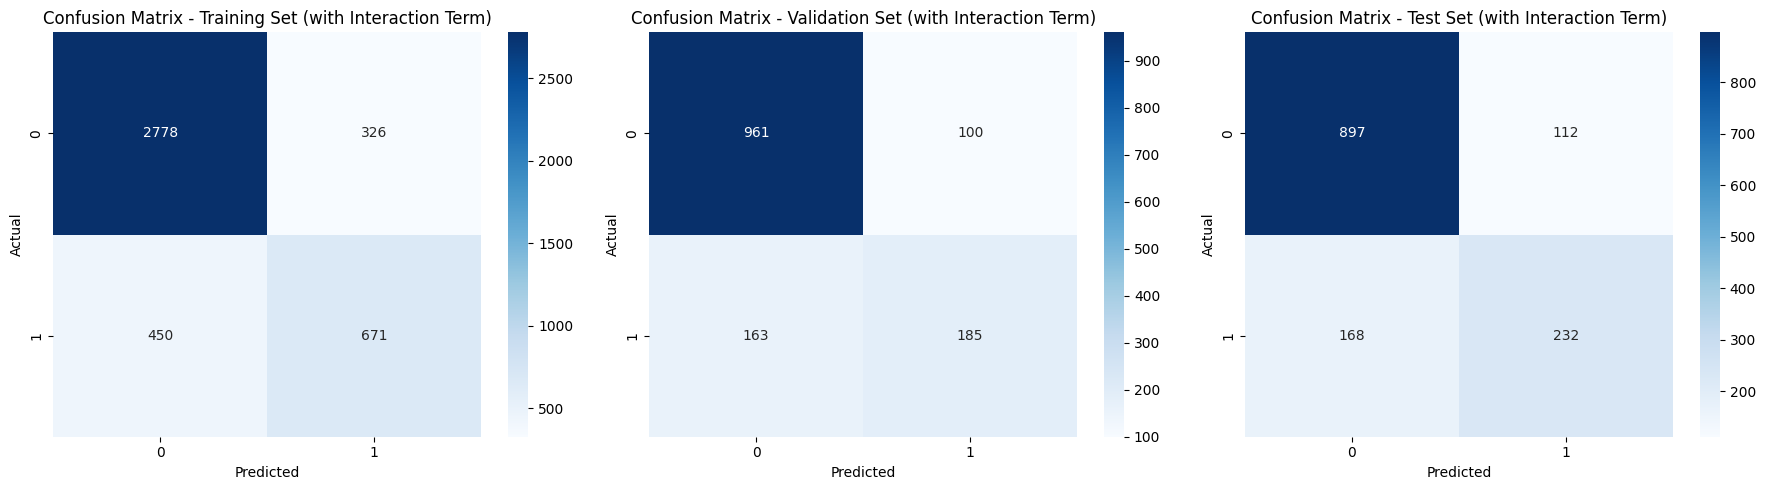

In [ ]:
# Calculate confusion matrix for the training set with interaction term
cm_train_interact = confusion_matrix(y_train, y_train_pred_interact)
print("Confusion Matrix - Training Set (with Interaction Term):")
print(cm_train_interact)

# Calculate confusion matrix for the validation set with interaction term
cm_val_interact = confusion_matrix(y_val, y_val_pred_interact)
print("\nConfusion Matrix - Validation Set (with Interaction Term):")
print(cm_val_interact)

# Calculate confusion matrix for the test set with interaction term
cm_test_interact = confusion_matrix(y_test, y_test_pred_interact)
print("\nConfusion Matrix - Test Set (with Interaction Term):")
print(cm_test_interact)

# Optional: Visualize Confusion Matrices with Interaction Term
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.heatmap(cm_train_interact, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix - Training Set (with Interaction Term)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(cm_val_interact, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('Confusion Matrix - Validation Set (with Interaction Term)')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

sns.heatmap(cm_test_interact, annot=True, fmt='d', cmap='Blues', ax=axes[2])
axes[2].set_title('Confusion Matrix - Test Set (with Interaction Term)')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')

plt.tight_layout()
plt.show()

The interaction model improves churn identification across all three partitions:
Training
- TP: 658 → 671 (+13)
- FN: 463 → 450 (−13)
- Recall: 58.70% → 59.86%
Validation
- TP: 180 → 185 (+5)
- FN: 168 → 163 (−5)
- Recall: 51.72% → 53.16%
Test
- TP: 225 → 232 (+7)
- FN: 175 → 168 (−7)
- Recall: 56.25% → 58.00%


The trade-off is that the interaction model produces slightly more false positives on the training and test sets:
- Test FP: 110 → 112
- Test TN: 899 → 897


Key conclusion
This is a positive result for the interaction term.

In [ ]:
# Show classification report for the training set with interaction term
print("Classification Report - Training Set (with Interaction Term):")
print(classification_report(y_train, y_train_pred_interact))

# Show classification report for the validation set with interaction term
print("\nClassification Report - Validation Set (with Interaction Term):")
print(classification_report(y_val, y_val_pred_interact))

# Show classification report for the test set with interaction term
print("\nClassification Report - Test Set (with Interaction Term):")
print(classification_report(y_test, y_test_pred_interact))

Classification Report - Training Set (with Interaction Term):
              precision    recall  f1-score   support

           0       0.86      0.89      0.88      3104
           1       0.67      0.60      0.63      1121

    accuracy                           0.82      4225
   macro avg       0.77      0.75      0.76      4225
weighted avg       0.81      0.82      0.81      4225


Classification Report - Validation Set (with Interaction Term):
              precision    recall  f1-score   support

           0       0.85      0.91      0.88      1061
           1       0.65      0.53      0.58       348

    accuracy                           0.81      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.80      0.81      0.81      1409


Classification Report - Test Set (with Interaction Term):
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1009
           1       0.67      0.58      0.62       4

Adding the Tenure Months × Monthly Charges interaction resulted in a small improvement in model performance.

On the test set, recall for churners increased from 0.56 to 0.58, while the F1 score increased from 0.61 to 0.62. Precision remained unchanged at 0.67 and overall accuracy remained at 0.80.

The interaction model therefore provides a modest improvement in identifying actual churners without materially affecting overall accuracy.

Combined with the fact that the interaction term is statistically significant (p < 0.001), the results support retaining this interaction in the model.

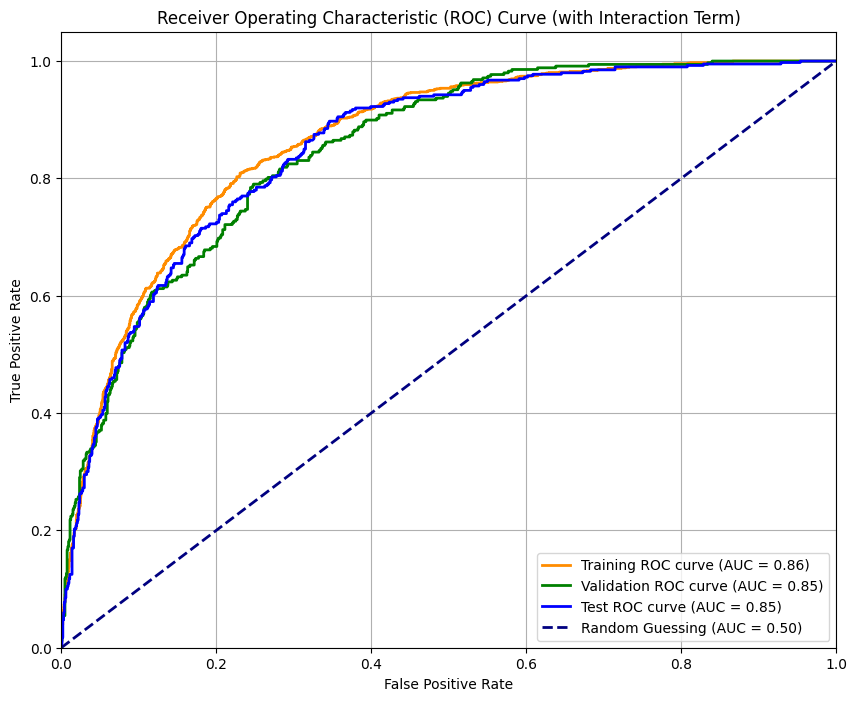

Training AUC (with Interaction Term): 0.8637
Validation AUC (with Interaction Term): 0.8506
Test AUC (with Interaction Term): 0.8539


In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Calculate ROC curve and AUC for the training set with interaction term
fpr_train_interact, tpr_train_interact, thresholds_train_interact = roc_curve(y_train, y_train_proba_interact)
roc_auc_train_interact = auc(fpr_train_interact, tpr_train_interact)

# Calculate ROC curve and AUC for the validation set with interaction term
fpr_val_interact, tpr_val_interact, thresholds_val_interact = roc_curve(y_val, y_val_proba_interact)
roc_auc_val_interact = auc(fpr_val_interact, tpr_val_interact)

# Calculate ROC curve and AUC for the test set with interaction term
fpr_test_interact, tpr_test_interact, thresholds_test_interact = roc_curve(y_test, y_test_proba_interact)
roc_auc_test_interact = auc(fpr_test_interact, tpr_test_interact)

# Plot ROC curves with interaction term
plt.figure(figsize=(10, 8))
plt.plot(fpr_train_interact, tpr_train_interact, color='darkorange', lw=2, label='Training ROC curve (AUC = %0.2f)' % roc_auc_train_interact)
plt.plot(fpr_val_interact, tpr_val_interact, color='green', lw=2, label='Validation ROC curve (AUC = %0.2f)' % roc_auc_val_interact)
plt.plot(fpr_test_interact, tpr_test_interact, color='blue', lw=2, label='Test ROC curve (AUC = %0.2f)' % roc_auc_test_interact)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guessing (AUC = 0.50)') # Diagonal line for random guessing
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve (with Interaction Term)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print(f"Training AUC (with Interaction Term): {roc_auc_train_interact:.4f}")
print(f"Validation AUC (with Interaction Term): {roc_auc_val_interact:.4f}")
print(f"Test AUC (with Interaction Term): {roc_auc_test_interact:.4f}")

And it has!  Everything has improved a bit with the addition of the interaction term.

# (13) Did adding the interaction term improve your model?  Why or why not?

The interaction model provided the best overall predictive performance. Adding the Tenure Months × Monthly Charges interaction improved the test AUC from 0.8510 for the reduced model to 0.8539, and slightly exceeded the full model AUC of 0.8518.

The interaction term was statistically significant (p < 0.001), indicating that the relationship between monthly charges and customer churn varies with customer tenure.

The model also achieved a churn recall of 58.0%, an improvement over the reduced model's 56.25%.

Overall, the interaction model provides a good balance between statistical significance, model simplicity, and predictive performance.

# (14) Make a final choice of which of the three models is best?  Justify your response.

I would select the Reduced Model + (Tenure Months × Monthly Charges) interaction as the best of the three models.

Justification:

The interaction model provides the strongest overall predictive performance on the unseen test data. Its test AUC of 0.8539 is higher than both the Full Model (0.8518) and the Reduced Model (0.8510).

AUC is particularly useful here because it measures the model's ability to distinguish between customers who churn and those who do not across different classification thresholds.


The interaction model also improves churn recall to 58.0%, compared with 56.25% for the reduced model, while maintaining the same overall test accuracy of 80%.

 In addition, the (Tenure Months × Monthly Charges) interaction is statistically significant (p < 0.001), indicating that the effect of monthly charges on churn depends on customer tenure.